# Training the model

Glosten–Milgrom says a market maker should widen each quote by the price move it expects **if that quote is filled**. The previous two notebooks built the data for estimating that move. For each of about 930,000 filled pretend quotes in January, we have:

- the **markout**: how far the price moved against the quote in the 30 s after it was filled (in log-odds);
- **16 features** describing the market at the moment the quote was posted.

Here we train a model that predicts the markout from the features. Its prediction is $\hat a$, the premium.

**The rules of the game**

- **Training days: 1–25 January. Validation days: 26–31 January.** The model never sees the validation days while learning. They're used to decide when to stop training and to judge every model fairly, on later races than it learned from. We split by whole days because quotes in the same race (and neighbouring quotes filled by the same move) are near-copies. A random split would let the model be tested on near-copies of what it trained on.
- **Each quote counts in proportion to its contracts filled**, in training and in every score.
- **The model has to earn its place.** We compare it with three simpler benchmarks, and only use it if it beats the lookup table on the validation days.
- **It has to be fast,** because the strategy will call it live. We measure that too.

**The plan**

1. Load the data and split it into training and validation days.
2. Fit three benchmarks: a single average, a lookup table, and a straight-line model.
3. Train LightGBM, stopping when it stops improving on the validation days.
4. Compare accuracy, with confidence intervals.
5. Check that the predictions are calibrated: when the model predicts 0.05, is the average markout about 0.05?
6. Check that it tells good fills from bad ones at the same quote distance.
7. See which features it relies on.
8. Measure its speed.
9. Retrain on all of January and save the final model.

In [1]:
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

# Project root = the folder that holds data/ (works whether this runs from adverse-selection/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "adverse-selection" / "data" / "features_jan.parquet"     # from building-features
MODEL_FILE = ROOT / "adverse-selection" / "adverse_model.txt"

FEATURES = ["side", "quote_distance", "ticks_from_best", "seconds_to_off", "mid_odds", "favourite",
            "spread_ticks", "half_spread", "imbalance_1", "imbalance_3", "move_5", "move_30", "vol_30",
            "traded_10", "traded_30", "flow_30"]
VALIDATION_DAYS = range(26, 32)          # 26-31 January
BIN_EDGES = [30, 45, 60, 90, 120, 180, 240, 300, 350]   # time bins for the lookup table (same as σ² and k)
BIN_NAMES = [f"({lo}, {hi}]" for lo, hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:])]
DISTANCE_BANDS = [0, 0.025, 0.05, 0.10, 0.20]
BAND_LABELS = ["0-0.025", "0.025-0.05", "0.05-0.10", "0.10-0.20"]

# LightGBM settings: small trees, and at least 200 quotes in every leaf
PARAMS = {"objective": "regression", "num_leaves": 15, "min_child_samples": 200,
          "learning_rate": 0.05, "verbose": -1, "seed": 42}
MAX_TREES, PATIENCE = 2000, 100          # stop after 100 trees without improvement on the validation days
N_BOOT = 1000
rng = np.random.default_rng(42)

RAMP = ["#5cbef4", "#1881e1", "#1d49a0", "#122056"]     # light = close to the mid, dark = far from it
# Chart style: blue = back quotes (and our estimate), orange = lay quotes, greys for everything else
BLUE = "#2a78d6"
COLOURS = {"back": BLUE, "lay": "#eb6834"}
GREY = "#898781"                    # secondary marks
LIGHT = "#c3c2b7"                   # background detail and reference lines
INK, INK_2 = "#0b0b0b", "#52514e"   # headlines; labels and tick numbers
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.labelpad": 6,
    "xtick.color": LIGHT, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.markeredgewidth": 1.5, "lines.markeredgecolor": "white",
    "legend.frameon": False, "legend.fontsize": 9.5,
})


def titles(ax, title, subtitle, gap=10):
    # A bold headline that states the finding, then a smaller line saying what is plotted. Both are kept out of
    # the layout, so in a figure with several panels they can run across all of them. `gap` (points) leaves
    # room for a panel title underneath.
    note = ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, gap), textcoords="offset points",
                       fontsize=9.5, color=INK_2, va="bottom", linespacing=1.45)
    head = ax.set_title(title, loc="left", fontsize=12.5, fontweight="semibold",
                        pad=gap + 6 + 14 * (subtitle.count("\n") + 1))
    note.set_in_layout(False)
    head.set_in_layout(False)


def legend(ax, **kwargs):
    # A legend whose keys drop the white ring around markers (on a short key it makes a line look dashed)
    for key in ax.legend(**kwargs).legend_handles:
        if isinstance(key, Line2D):
            key.set_markeredgewidth(0)


## Step 1: Training and validation days

In [2]:
data = pd.read_parquet(DATA)
is_validation = data["day"].isin(VALIDATION_DAYS)
train, valid = data[~is_validation], data[is_validation]

pd.DataFrame({
    "days": ["1-25 January", "26-31 January"],
    "races": [train["market_id"].nunique(), valid["market_id"].nunique()],
    "filled quotes": [len(train), len(valid)],
    "contracts filled": [train["contracts_filled"].sum().round(), valid["contracts_filled"].sum().round()],
}, index=["training", "validation"])

,days,races,filled quotes,contracts filled
training,1-25 January,3166,738121,6077723.0
validation,26-31 January,787,190693,1541731.0


## Step 2: Three simple benchmarks

Every model is scored by its **mean squared error** on the validation days: the contract-weighted average of (actual markout − prediction)². Lower is better. Three simple models set the bar:

1. **One number for everything:** the average markout on the training days. Any useful model has to beat this.
2. **A lookup table:** the average markout for each time bin (the same bins as the σ² and k notebooks) and each side. This is what the strategy would use without a model.
3. **A straight-line model:** prediction = intercept + a weight × each feature, fitted by weighted least squares. Features are put on the same scale first (minus their mean, divided by their standard deviation), and the few missing values are filled with the training median. It uses the same 16 features as LightGBM but can't bend: it can't capture U-shapes like the one for `move_5`, or the way features combine.

In [3]:
def weighted_mse(actual, predicted, weight):
    return np.average((actual - predicted) ** 2, weights=weight)


w_train, w_valid = train["contracts_filled"], valid["contracts_filled"]
predictions = {}

# 1. One number for everything
average = np.average(train["markout"], weights=w_train)
predictions["one average"] = np.full(len(valid), average)

# 2. Lookup table: average markout by time bin and side
def table_cell(df):
    # Each quote's cell in the table: its time bin and its side
    return [pd.cut(df["seconds_to_off"], BIN_EDGES, labels=BIN_NAMES).astype(str).rename("seconds before off"),
            pd.Series(np.where(df["side"] == 1, "back", "lay"), index=df.index, name="side")]

cell = table_cell(train)
table = (train["markout"] * w_train).groupby(cell).sum() / w_train.groupby(cell).sum()
predictions["lookup table"] = table.reindex(pd.MultiIndex.from_arrays(table_cell(valid))).fillna(average).to_numpy()

# 3. Straight-line model on standardised features
median = train[FEATURES].median()
centre, scale = train[FEATURES].fillna(median).mean(), train[FEATURES].fillna(median).std()

def design(df):
    return np.column_stack([np.ones(len(df)), ((df[FEATURES].fillna(median) - centre) / scale).to_numpy()])

root_w = np.sqrt(w_train.to_numpy())                       # weighted least squares = ordinary on sqrt(w)-scaled rows
coefficients = np.linalg.lstsq(design(train) * root_w[:, None], train["markout"].to_numpy() * root_w, rcond=None)[0]
predictions["straight line"] = design(valid) @ coefficients

print("The lookup table (average markout on the training days, log-odds):")
table.unstack("side").reindex(BIN_NAMES).round(4)

The lookup table (average markout on the training days, log-odds):


side,back,lay
seconds before off,,
"(30, 45]",0.0239,0.0297
"(45, 60]",0.0259,0.0278
"(60, 90]",0.0291,0.0300
"(90, 120]",0.0294,0.0364
"(120, 180]",0.0342,0.0422
"(180, 240]",0.0434,0.0561
"(240, 300]",0.0591,0.0619
"(300, 350]",0.0513,0.0743


## Step 3: LightGBM

LightGBM builds **gradient-boosted trees**. A decision tree splits the quotes into groups using simple yes/no questions ("is `quote_distance` above 0.04?", "is `seconds_to_off` below 120?") and predicts each group's average. One tree is crude, so boosting adds trees one at a time. Each new tree is fitted to whatever the trees so far still get wrong, and only a small step of it is added (the learning rate, 0.05). Hundreds of small trees together can follow curves and combinations of features that a straight line can't.

The settings are deliberately conservative. Trees have at most 15 leaves, and every leaf needs at least 200 quotes, which keeps each tree simple and stops it chasing noise.

**When to stop.** More trees always fit the training days better, but past some point they start learning noise and get worse on new data. So after each tree we check the error on the validation days, and stop once it hasn't improved for 100 trees in a row. The best number of trees is the one with the lowest validation error.

Trained in 1.2 s; best number of trees: 220
121 trees already get within 0.1% of the best validation error


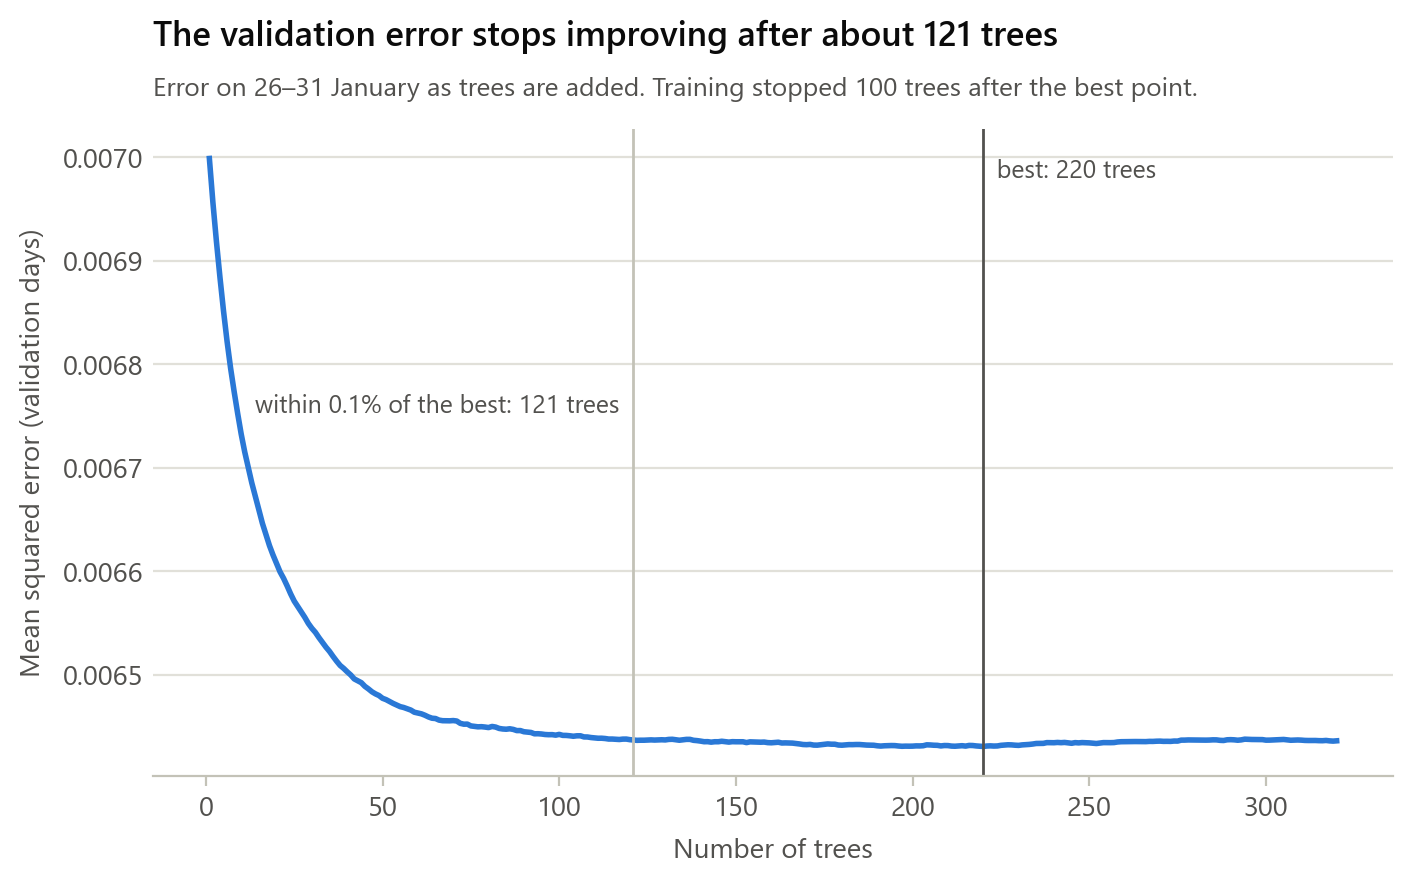

In [4]:
train_set = lgb.Dataset(train[FEATURES], train["markout"], weight=w_train)
valid_set = lgb.Dataset(valid[FEATURES], valid["markout"], weight=w_valid, reference=train_set)

history = {}
start = time.perf_counter()
model = lgb.train(PARAMS, train_set, num_boost_round=MAX_TREES, valid_sets=[valid_set], valid_names=["validation"],
                  callbacks=[lgb.early_stopping(PATIENCE, verbose=False), lgb.record_evaluation(history)])
TREES = model.best_iteration
print(f"Trained in {time.perf_counter() - start:.1f} s; best number of trees: {TREES}")
predictions["LightGBM"] = model.predict(valid[FEATURES], num_iteration=TREES)

curve = np.array(history["validation"]["l2"])
nearly_as_good = np.argmax(curve <= curve.min() * 1.001) + 1      # fewest trees within 0.1% of the best error
print(f"{nearly_as_good} trees already get within 0.1% of the best validation error")
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(curve) + 1), curve, color=BLUE)
middle = curve.min() + 0.6 * (curve.max() - curve.min())
for trees, text, height in [(nearly_as_good, f"within 0.1% of the best: {nearly_as_good} trees", middle),
                            (TREES, f"best: {TREES} trees", curve.max())]:
    ax.axvline(trees, color=LIGHT if trees == nearly_as_good else INK_2, lw=1)
    left = trees == nearly_as_good                            # this label sits to the left of its line
    ax.text(trees, height, f"{text}  " if left else f"  {text}", ha="right" if left else "left", va="top",
            fontsize=9, color=INK_2)
ax.set(xlabel="Number of trees", ylabel="Mean squared error (validation days)")
titles(ax, f"The validation error stops improving after about {nearly_as_good} trees",
       f"Error on 26–31 January as trees are added. Training stopped {PATIENCE} trees after the best point.")
plt.show()

The error drops quickly over the first 100 trees and then barely moves. The lowest point is at 220 trees, but 121 trees already get within 0.1% of it. That flat stretch matters for speed (Step 8): fewer trees means faster predictions.

## Step 4: How accurate is it?

Below is each model's mean squared error on the validation days, and its **share of the variation explained**:

$$1 - \frac{\text{model's error}}{\text{error of the one-average model}}$$

This is the out-of-sample $R^2$. Markouts are mostly noise (nobody can predict exactly where a price will be in 30 s), so a few percent is normal and anything near 10% is good.

To check that LightGBM's edge over the lookup table is real, we bootstrap the validation races, the same way as in the earlier notebooks. We redraw 787 races with replacement 1,000 times and recompute how much lower LightGBM's error is each time. If the 95% interval stays above zero, the improvement isn't luck.

In [5]:
actual = valid["markout"].to_numpy()
errors = {name: weighted_mse(actual, p, w_valid) for name, p in predictions.items()}
accuracy = pd.DataFrame({"mean squared error": errors,
                         "share of variation explained": {n: 1 - e / errors["one average"] for n, e in errors.items()}})
print(accuracy.round(5), "\n")

# Bootstrap by race: how much lower is LightGBM's error than the lookup table's?
race = valid["market_id"].to_numpy()
races = pd.unique(race)
squared = pd.DataFrame({name: w_valid * (actual - predictions[name]) ** 2 for name in ["lookup table", "LightGBM"]})
per_race = squared.groupby(race).sum().reindex(races)
weight_per_race = w_valid.groupby(race).sum().reindex(races).to_numpy()
draws = rng.multinomial(len(races), np.full(len(races), 1 / len(races)), size=N_BOOT)
table_error = draws @ per_race["lookup table"].to_numpy() / (draws @ weight_per_race)
model_error = draws @ per_race["LightGBM"].to_numpy() / (draws @ weight_per_race)
improvement = np.sort(1 - model_error / table_error)
low, high = improvement[24], improvement[974]
print(f"LightGBM's error is {1 - errors['LightGBM'] / errors['lookup table']:.1%} lower than the lookup table's "
      f"(95% CI {low:.1%} to {high:.1%})")
print("Our rule (use the model only if it beats the table):",
      "PASSED" if errors["LightGBM"] < errors["lookup table"] else "FAILED")

               mean squared error  share of variation explained
one average               0.00705                       0.00000
lookup table              0.00688                       0.02401
straight line             0.00659                       0.06431
LightGBM                  0.00643                       0.08748 

LightGBM's error is 6.5% lower than the lookup table's (95% CI 5.3% to 7.7%)
Our rule (use the model only if it beats the table): PASSED


On days it never trained on, LightGBM explains about 8.7% of the variation in markouts, against 2.4% for the lookup table and 6.4% for the straight line. Its error is 6.5% lower than the lookup table's, and the bootstrap interval (5.3% to 7.7%) is well clear of zero, so the improvement is real. **It passes our rule.**

The straight line already does much better than the table, because it uses all 16 features rather than just time and side. LightGBM's extra gain comes from what a straight line can't do: curves, U-shapes, and features working together.

**Does it win on every day?** The bootstrap pools the six validation days. A sterner test is to compare the model with the lookup table on each day separately. If it only won on one or two lively days, we'd trust it less.

In [6]:
day = valid["day"].to_numpy()
by_day = pd.DataFrame({name: squared[name].groupby(day).sum() / w_valid.groupby(day).sum()
                       for name in ["lookup table", "LightGBM"]})
by_day["error reduction (%)"] = 100 * (1 - by_day["LightGBM"] / by_day["lookup table"])
by_day.index.name = "January"
by_day.round(6)

,lookup table,LightGBM,error reduction (%)
January,,,
26,0.007813,0.006995,10.462183
27,0.005533,0.005050,8.727131
28,0.007023,0.006753,3.854483
29,0.006618,0.006281,5.091839
30,0.007474,0.006931,7.258825
31,0.006977,0.006621,5.103324


LightGBM's error is lower than the lookup table's on every one of the six days, by between 3.9% and 10.5%. So the gain isn't down to one or two unusual days.

## Step 5: Are the predictions calibrated?

The premium is added straight onto our quotes, so a prediction of 0.05 should mean an average markout of about 0.05, not just "more than average". We sort the validation quotes by their prediction, cut them into ten equal groups, and compare each group's average prediction with its average actual markout. Calibrated predictions sit on the 45° line.

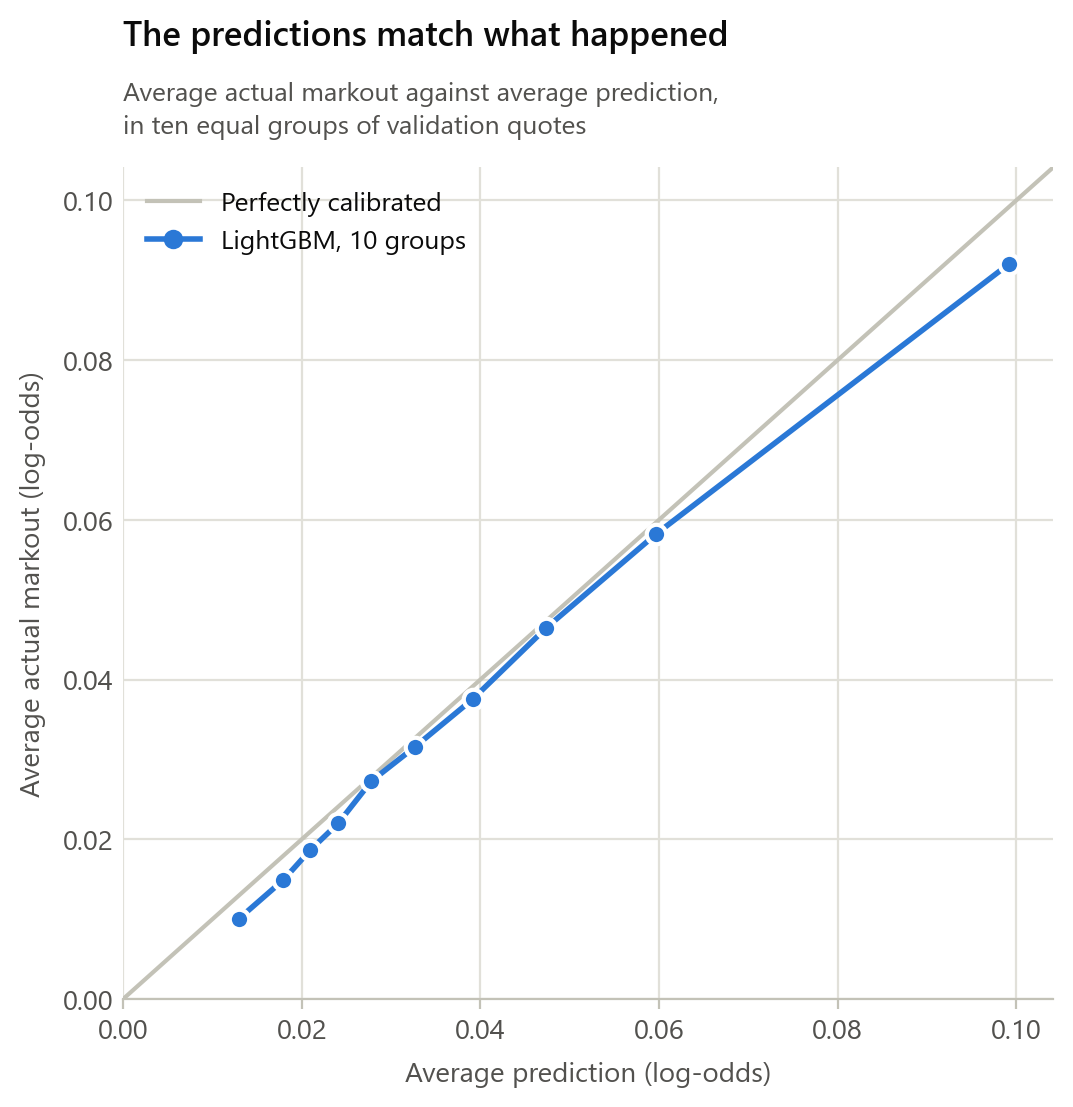

In [7]:
check = valid.assign(predicted=predictions["LightGBM"])
check["group"] = pd.qcut(check["predicted"], 10, labels=False)
weighted = check[["predicted", "markout"]].mul(check["contracts_filled"], axis=0)
calibration = weighted.groupby(check["group"]).sum().div(check["contracts_filled"].groupby(check["group"]).sum(), axis=0)

fig, ax = plt.subplots(figsize=(6, 5.4))
top = calibration.to_numpy().max() * 1.05
ax.plot([0, top], [0, top], color=LIGHT, lw=1.5, label="Perfectly calibrated")
ax.plot(calibration["predicted"], calibration["markout"], "-o", color=BLUE, label="LightGBM, 10 groups")
ax.set(xlim=(0, top), ylim=(0, top), xlabel="Average prediction (log-odds)", ylabel="Average actual markout (log-odds)")
ax.grid(True, axis="x")
legend(ax, loc="upper left")
titles(ax, "The predictions match what happened",
       "Average actual markout against average prediction,\nin ten equal groups of validation quotes")
plt.show()

The dots sit close to the 45° line across the whole range, so the predictions can be used as they are. They run slightly high overall, most visibly in the top group: the model predicts about 0.099 there, and the actual average is about 0.092. That's common for this kind of model. For a premium, slightly overcharging is the safer direction to be wrong in.

## Step 6: Does it pick out the bad fills?

A lower error is good, but what matters for profit is whether the model can tell bad fills from good ones.

For each filled quote, what we actually make, per contract and in log-odds, is

$$\text{net} = \underbrace{\text{quote distance}}_{\text{spread captured}} - \underbrace{\text{markout}}_{\text{adverse selection}}.$$

The spread captured is how far from the mid we traded, and the markout is how far the price then moved against us. Both are measured from the mid at posting.

A quote further from the mid captures more spread but also tends to have a bigger markout. If we sorted all quotes by prediction at once, we'd mostly be sorting them by distance. So we compare like with like. Within each distance band, we sort the quotes by their predicted markout and cut them into five equal groups. If the model works, the groups it rates as most dangerous should earn much less than the ones it rates as safe, even though they were quoted at the same distance.

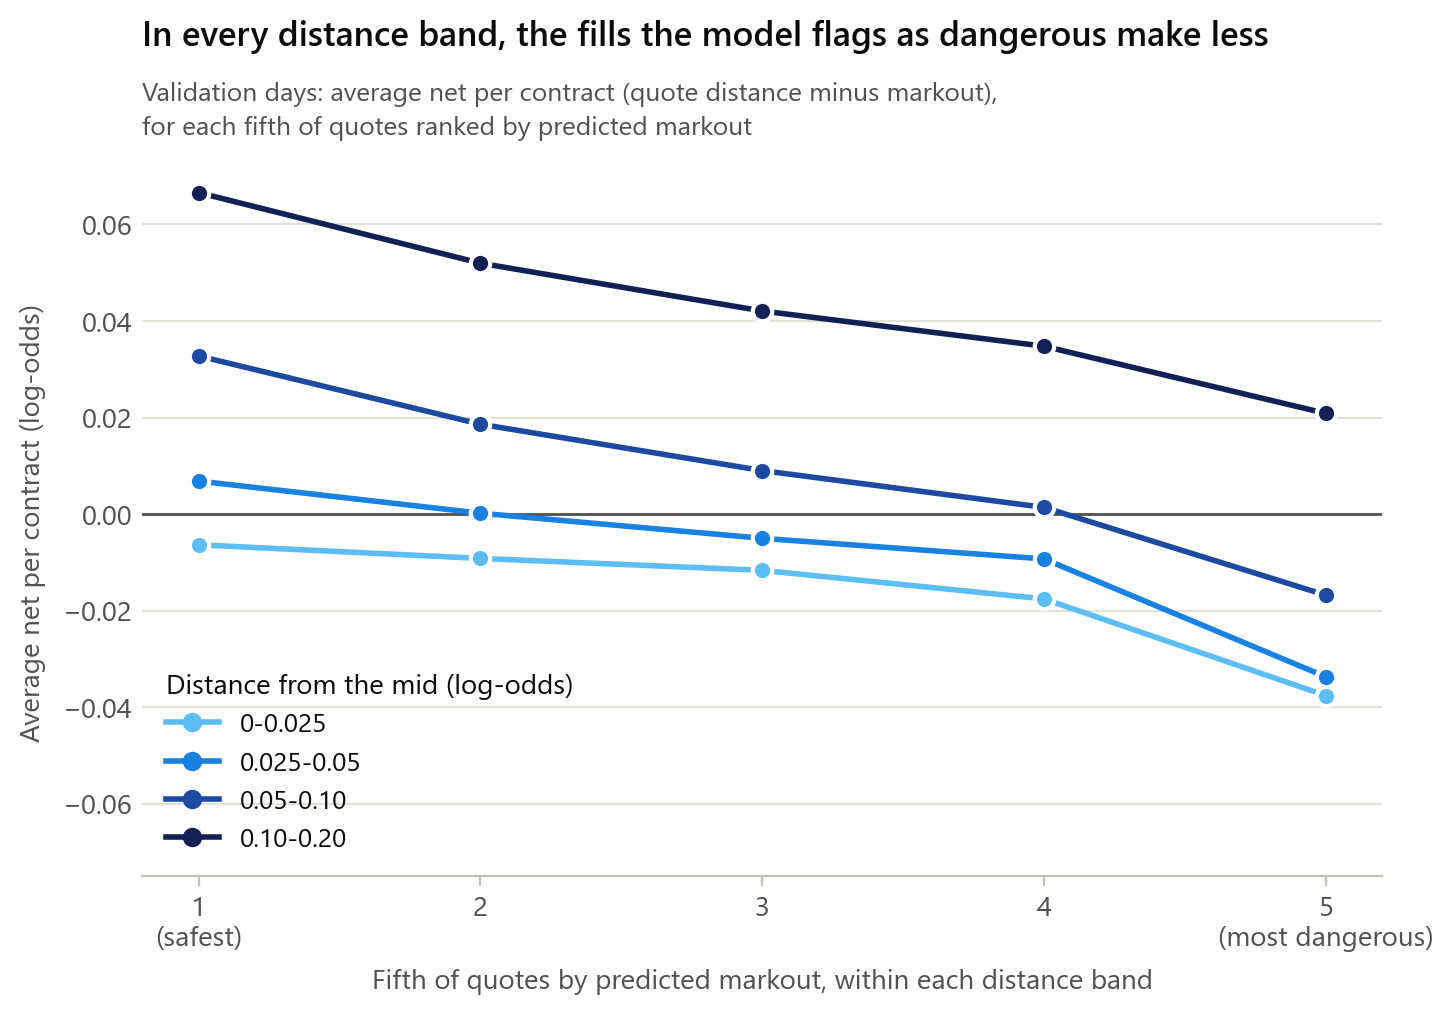

predicted markout  actual markout     net
band       fifth                                           
0-0.025    0                 0.0141          0.0110 -0.0064
           1                 0.0196          0.0170 -0.0092
           2                 0.0239          0.0219 -0.0117
           3                 0.0303          0.0295 -0.0176
           4                 0.0500          0.0496 -0.0376
0.025-0.05 0                 0.0249          0.0252  0.0068
           1                 0.0348          0.0328  0.0002
           2                 0.0419          0.0403 -0.0050
           3                 0.0500          0.0473 -0.0093
           4                 0.0743          0.0717 -0.0337
0.05-0.10  0                 0.0351          0.0322  0.0328
           1                 0.0502          0.0467  0.0186
           2                 0.0600          0.0592  0.0090
           3                 0.0715          0.0708  0.0014
           4                 0.1033          0.0938 -0.0168
0.10-0.20  0                 0.0599          0.0533  0.0666
           1                 0.0799          0.0745  0.0520
           2                 0.0952          0.0934  0.0421
           3                 0.1135          0.1076  0.0348
           4                 0.1554          0.1294  0.0208

In [8]:
check["net"] = check["quote_distance"] - check["markout"]
check["band"] = pd.cut(check["quote_distance"], DISTANCE_BANDS, labels=BAND_LABELS)
check["fifth"] = check.groupby("band", observed=True)["predicted"].transform(lambda p: pd.qcut(p, 5, labels=False))
weighted = check[["predicted", "markout", "net"]].mul(check["contracts_filled"], axis=0)
groups = [check["band"], check["fifth"]]
by_fifth = weighted.groupby(groups, observed=True).sum().div(
    check["contracts_filled"].groupby(groups, observed=True).sum(), axis=0)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.axhline(0, color=INK_2, lw=1)
for band, colour in zip(BAND_LABELS, RAMP):
    ax.plot(np.arange(1, 6), by_fifth.loc[band, "net"], "-o", color=colour, label=band)
ax.set_xticks(range(1, 6), ["1\n(safest)", "2", "3", "4", "5\n(most dangerous)"])
ax.set(xlabel="Fifth of quotes by predicted markout, within each distance band",
       ylabel="Average net per contract (log-odds)")
ax.set_ylim(bottom=-0.075)
legend(ax, title="Distance from the mid (log-odds)", loc="lower left", alignment="left")
titles(ax, "In every distance band, the fills the model flags as dangerous make less",
       "Validation days: average net per contract (quote distance minus markout),\n"
       "for each fifth of quotes ranked by predicted markout")
plt.show()

by_fifth.rename(columns={"predicted": "predicted markout", "markout": "actual markout"}).round(4)

In every distance band, what we make falls steadily from the safest fifth to the most dangerous. So the model tells good fills from bad ones even at the same quote distance:

- **0.05–0.10 from the mid:** the safest fifth makes +0.033 per contract and the most dangerous loses 0.017.
- **0.025–0.05:** from +0.007 down to −0.034.
- **Under 0.025:** these quotes lose on average in every group, because they capture almost no spread. But the most dangerous fifth loses about six times as much as the safest (−0.038 against −0.006).
- **0.10–0.20:** these make money in every group, and the model still ranks them in the right order.

That's the pattern we want: clearly negative in the top group and clearly positive in the bottom one, in the middle distances where A–S is likely to quote. It's also why the premium matters. Without it, the strategy would quote the same distance into the most dangerous fifth as into the safest.

## Step 7: What the model relies on

For every prediction, LightGBM can split the prediction into a contribution from each feature: how much that feature pushed this quote's prediction above or below the average. These are **SHAP values**. Averaging their size over the validation quotes shows how much each feature matters to the model overall.

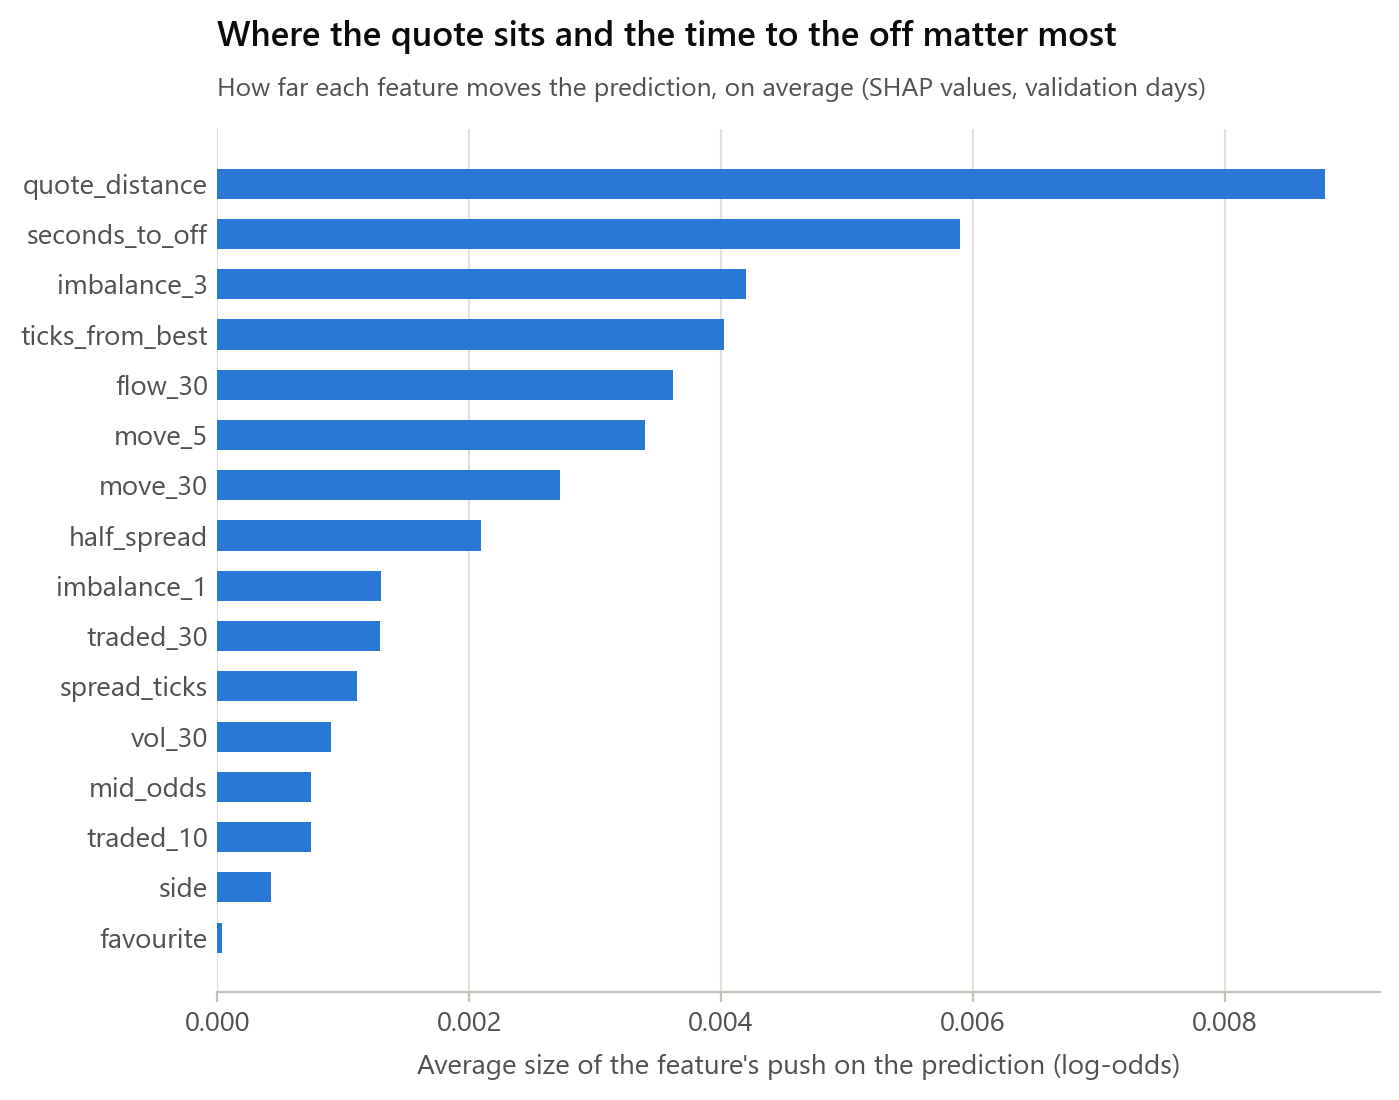

In [9]:
contributions = model.predict(valid[FEATURES], num_iteration=TREES, pred_contrib=True)[:, :-1]   # last column = average
importance = pd.Series(np.average(np.abs(contributions), axis=0, weights=w_valid), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.barh(importance.index, importance, color=BLUE, height=0.6)
ax.set(xlabel="Average size of the feature's push on the prediction (log-odds)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", length=0)
ax.set_axisbelow(True)
titles(ax, "Where the quote sits and the time to the off matter most",
       "How far each feature moves the prediction, on average (SHAP values, validation days)")
plt.show()

Where the quote sits (`quote_distance`, `ticks_from_best`) and the time to the off matter most, as the first look in the previous notebook suggested.

Next come the order-book and order-flow features: `imbalance_3`, `flow_30` and the recent moves `move_5` and `move_30`. These are the ones that say something about who is trading right now, which is what Glosten–Milgrom is about. `imbalance_3` looked nearly flat on its own in the previous notebook, but it matters once it's combined with the other features.

`favourite` adds almost nothing, and `side` adds little once the other features are known.

## Step 8: Is it fast enough?

Live, the strategy needs one prediction per runner and side whenever it updates its quotes. That's about 6–10 rows at a time, and every row of a call is predicted together. So we time one call with 10 rows, repeated many times, for LightGBM, the straight-line model and the lookup table. For scale, Betfair sends updates every 50–100 milliseconds (50,000–100,000 microseconds), and our orders take 200 milliseconds to arrive.

In [9]:
batch = valid[FEATURES].iloc[:10]
batch_array = batch.to_numpy()
batch_cells = list(zip(*table_cell(batch)))
table_dict = table.to_dict()


def microseconds_per_call(predict, repeats=2000):
    predict()                                    # warm up once
    start = time.perf_counter()
    for _ in range(repeats):
        predict()
    return (time.perf_counter() - start) / repeats * 1e6


# The straight line done the way it would be live: plain numpy on an array, no pandas
fill, mean, sd = median.to_numpy(), centre.to_numpy(), scale.to_numpy()

def straight_line(x):
    x = np.where(np.isnan(x), fill, x)
    return coefficients[0] + ((x - mean) / sd) @ coefficients[1:]


speed = pd.Series({
    "LightGBM": microseconds_per_call(lambda: model.predict(batch_array, num_iteration=TREES, num_threads=1)),
    f"LightGBM, {nearly_as_good} trees": microseconds_per_call(
        lambda: model.predict(batch_array, num_iteration=nearly_as_good, num_threads=1)),
    "straight line": microseconds_per_call(lambda: straight_line(batch_array)),
    "lookup table": microseconds_per_call(lambda: [table_dict.get(c, average) for c in batch_cells]),
}, name="microseconds per call (10 rows)")
speed.round(1).to_frame()

,microseconds per call (10 rows)
LightGBM,54.4
"LightGBM, 121 trees",34.8
straight line,4.6
lookup table,0.4


LightGBM takes about 50 microseconds to predict 10 quotes. That's roughly a thousand times shorter than the gap between Betfair updates, so live speed isn't a concern. The cost grows with the number of trees: the 121-tree version, within 0.1% of the best error (Step 3), takes about three-quarters of the time. The straight line (about 4 microseconds) and the lookup table (under 1 microsecond) are faster still, but less accurate.

Speed does add up in backtesting, which replays every update of every race. A few thousand updates in each race's quoting window, at about 50 microseconds each, comes to around a sixth of a second per race. Predicting only when the strategy actually changes a quote would cut that further.

## Step 9: The final model

Early stopping picked the number of trees using the validation days. Now that it's chosen, the final model is retrained on **all of January** with that many trees, so it learns from every day we have. It's saved as a small text file (`adverse_model.txt`) that the strategy can load. The file also records the feature names and their order.

In [10]:
all_days = lgb.Dataset(data[FEATURES], data["markout"], weight=data["contracts_filled"])
final_model = lgb.train(PARAMS, all_days, num_boost_round=TREES)
final_model.save_model(str(MODEL_FILE))
print(f"Final model: {TREES} trees trained on {len(data):,} quotes from all of January")
print(f"Saved to {MODEL_FILE.relative_to(ROOT).as_posix()} ({MODEL_FILE.stat().st_size / 1024:.0f} KB)")

Final model: 220 trees trained on 928,814 quotes from all of January
Saved to adverse-selection/adverse_model.txt (399 KB)


The model is saved and ready for the strategy. Using it live needs two more pieces of work:

1. **The features, live.** The strategy has to compute the 16 features from the live order book exactly as `building-features.ipynb` does. Small rolling buffers per runner can hold the last 30 s of mids and trades.
2. **The quote distance.** `quote_distance` and `ticks_from_best` describe our own quote, but the premium itself moves the quote. So we measure them for the A–S quote *before* the premium is added, predict once, clip the prediction to between 0 and 0.15, and convert it to probability units with $\hat a \, S(1-S)$.

The real test is then a February backtest: A–S with the premium against A–S without it.